# 01 — Quick checks on the 300 pilot questions (Plan Step 1)

**Goal:** before scaling to 1,000 questions, check that Lift is not just relevance under another name.

**Input:** `halt_rag_v5_signals.csv` in your data folder (`data\` on the laptop, Drive on Colab), written by the last cell of `HALT_RAG_v5_signals.ipynb`.
If it is missing, run that notebook to the end first.

**What this notebook reports**
1. How closely the six signals move together (Spearman).
2. Each signal's own AUROC against the label, and against popularity (head vs tail).
3. Lift vs relevance: correlation, and whether Lift adds anything on top of relevance.
4. AUROC inside head only and inside tail only.
5. The Step 1 decision.

In [1]:
# ── Setup: works on a laptop (VS Code) and on Colab ───────────────────────
import os, sys, subprocess
ON_COLAB = "google.colab" in sys.modules
if ON_COLAB:
    # Colab: get the code from GitHub (push your latest commit first) and mount Drive
    REPO, BRANCH = "/content/HALT-RAG", "lift_signal"
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", "-b", BRANCH,
                        "https://github.com/Shaithra2107/HALT-RAG", REPO], check=True)
    else:
        subprocess.run(["git", "-C", REPO, "pull", "-q"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
else:
    # laptop: this notebook sits in <repo>/notebooks, so the repo is one level up
    REPO = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(REPO, "src"))

from halt_rag.config import load_config, data_path, data_dir
cfg = load_config(os.path.join(REPO, "config.yaml"))
print("running on:", "Colab" if ON_COLAB else "laptop", "| data folder:", data_dir(cfg))

running on: laptop | data folder: E:\shaithu\4th Year\IRP\halt-rag-repo\HALT-RAG\data


In [2]:
import numpy as np, pandas as pd, json
from halt_rag.signals import SIGNALS
from halt_rag.eval.metrics import signal_table, within_band_auroc, correlation_matrix, auroc_ci

path = data_path(cfg, "signals_v5")
assert os.path.exists(path), f"Not found: {path}\nRun HALT_RAG_v5_signals.ipynb to the end first."
df = pd.read_csv(path)
print(f"{len(df)} rows | columns: {list(df.columns)}")

signals = [s for s in SIGNALS + ["cas_mean"] if s in df.columns]
targets = [t for t in ["y_judge", "y_cov", "y_gen"] if t in df.columns]
print("signals:", signals)
print("labels :", {t: f"{int(df[t].sum())}/{len(df)}" for t in targets})
print("bands  :", df["band"].value_counts().to_dict())

300 rows | columns: ['question', 'answers_list', 'band', 'wiki_title', 'm2_status', 'm2_match', 'm3_covered', 'answer_string_match', 'passage_1', 'title_1', 'passage_2', 'title_2', 'passage_3', 'title_3', 'passage_4', 'title_4', 'passage_5', 'title_5', 'gold_answers', 'evidence_label', 'evidence_reason', 'm2_match_v5', 'm2_status_v5', 'lift', 'relevance', 'consistency', 'rand_mu', 'rand_sd', 'ret_idx', 'kw_coverage', 'clarity', 'cas', 'cas_mean', 'cas_soft', 'answers', 'gen_ctx', 'y_gen', 'y_judge', 'y_cov', 'is_tail', 'evaluable']
signals: ['lift', 'relevance', 'consistency', 'kw_coverage', 'clarity', 'cas', 'cas_mean']
labels : {'y_judge': '124/300', 'y_cov': '123/300', 'y_gen': '106/300'}
bands  : {'tail': 150, 'head': 150}


## Sanity: Lift recomputed with ε
`lift = (relevance − rand_mu) / max(rand_sd, ε)`. Should match the stored Lift (rand_sd is never near 0 in the pilot).

In [3]:
eps = cfg["signals"]["lift_eps"]
lift_eps = (df["relevance"] - df["rand_mu"]) / np.maximum(df["rand_sd"], eps)
print("max |difference| vs stored lift:", float((lift_eps - df["lift"]).abs().max()))
print("smallest rand_sd:", float(df["rand_sd"].min()))

max |difference| vs stored lift: 0.0
smallest rand_sd: 0.07008100301027298


## 1. How closely the signals move together (Spearman)

In [4]:
corr = correlation_matrix(df, signals)
display(corr.round(2).style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1))

,lift,relevance,consistency,kw_coverage,clarity,cas,cas_mean
lift,1.000000,0.780000,0.520000,0.350000,-0.110000,0.360000,0.310000
relevance,0.780000,1.000000,0.690000,0.360000,-0.060000,0.440000,0.350000
consistency,0.520000,0.690000,1.000000,0.010000,0.050000,0.120000,0.150000
kw_coverage,0.350000,0.360000,0.010000,1.000000,-0.260000,0.430000,0.310000
clarity,-0.110000,-0.060000,0.050000,-0.260000,1.000000,-0.170000,-0.170000
cas,0.360000,0.440000,0.120000,0.430000,-0.170000,1.000000,0.720000
cas_mean,0.310000,0.350000,0.150000,0.310000,-0.170000,0.720000,1.000000


## 2. Each signal on its own
`auroc_label` = how well it separates good from bad passage sets.
`auroc_popularity` = how well it separates head from tail.
`popularity_detector = True` means it tracks popularity more than the label.

Scopes: **all 300**, and **evaluable** (subject page found, so the label means something).

In [5]:
n_boot, seed = cfg["eval"]["n_bootstrap"], cfg["seed"]
scopes = {"all": df}
if "m2_status_v5" in df.columns:
    scopes["evaluable"] = df[df["m2_status_v5"] != "not_in_kilt"]
tables = {}
for scope, d in scopes.items():
    for t in targets:
        tab = signal_table(d, signals, t, n_boot=n_boot, seed=seed)
        tables[f"{scope}|{t}"] = tab
        print(f"\n=== scope={scope} (n={len(d)}) | label={t} (pos={int(d[t].sum())}) ===")
        display(tab.round(3))


=== scope=all (n=300) | label=y_judge (pos=124) ===


,auroc_label,label_low,label_high,auprc_label,auroc_popularity,pop_low,pop_high,popularity_detector
signal,,,,,,,,
lift,0.708,0.649,0.765,0.633,0.557,0.491,0.622,False
relevance,0.738,0.680,0.794,0.665,0.533,0.470,0.595,False
consistency,0.638,0.573,0.701,0.531,0.506,0.440,0.570,False
kw_coverage,0.597,0.533,0.659,0.458,0.694,0.635,0.750,True
clarity,0.524,0.457,0.591,0.466,0.351,0.292,0.414,True
cas,0.795,0.737,0.843,0.749,0.547,0.481,0.615,False
cas_mean,0.646,0.584,0.707,0.538,0.604,0.538,0.670,False



=== scope=all (n=300) | label=y_cov (pos=123) ===


,auroc_label,label_low,label_high,auprc_label,auroc_popularity,pop_low,pop_high,popularity_detector
signal,,,,,,,,
lift,0.748,0.691,0.803,0.677,0.557,0.491,0.622,False
relevance,0.796,0.742,0.844,0.742,0.533,0.470,0.595,False
consistency,0.670,0.607,0.728,0.564,0.506,0.440,0.570,False
kw_coverage,0.658,0.600,0.720,0.517,0.694,0.635,0.750,True
clarity,0.423,0.356,0.490,0.385,0.351,0.292,0.414,True
cas,0.834,0.782,0.883,0.823,0.547,0.481,0.615,False
cas_mean,0.717,0.655,0.777,0.639,0.604,0.538,0.670,False



=== scope=all (n=300) | label=y_gen (pos=106) ===


,auroc_label,label_low,label_high,auprc_label,auroc_popularity,pop_low,pop_high,popularity_detector
signal,,,,,,,,
lift,0.722,0.662,0.778,0.575,0.557,0.491,0.622,False
relevance,0.752,0.690,0.809,0.596,0.533,0.470,0.595,False
consistency,0.623,0.553,0.690,0.456,0.506,0.440,0.570,False
kw_coverage,0.608,0.546,0.670,0.405,0.694,0.635,0.750,True
clarity,0.505,0.438,0.579,0.383,0.351,0.292,0.414,True
cas,0.809,0.750,0.860,0.747,0.547,0.481,0.615,False
cas_mean,0.642,0.573,0.708,0.498,0.604,0.538,0.670,False


... (2 outputs left out)


=== scope=evaluable (n=134) | label=y_cov (pos=108) ===


,auroc_label,label_low,label_high,auprc_label,auroc_popularity,pop_low,pop_high,popularity_detector
signal,,,,,,,,
lift,0.537,0.413,0.662,0.828,0.621,0.525,0.713,True
relevance,0.601,0.482,0.720,0.861,0.641,0.544,0.733,True
consistency,0.561,0.434,0.679,0.830,0.669,0.574,0.757,True
kw_coverage,0.530,0.408,0.649,0.823,0.616,0.525,0.705,True
clarity,0.498,0.368,0.634,0.807,0.253,0.176,0.337,True
cas,0.848,0.774,0.919,0.961,0.473,0.373,0.573,False
cas_mean,0.759,0.662,0.849,0.931,0.565,0.464,0.662,False



=== scope=evaluable (n=134) | label=y_gen (pos=90) ===


,auroc_label,label_low,label_high,auprc_label,auroc_popularity,pop_low,pop_high,popularity_detector
signal,,,,,,,,
lift,0.516,0.405,0.622,0.690,0.621,0.525,0.713,True
relevance,0.527,0.423,0.635,0.681,0.641,0.544,0.733,True
consistency,0.465,0.351,0.572,0.635,0.669,0.574,0.757,True
kw_coverage,0.472,0.365,0.577,0.646,0.616,0.525,0.705,True
clarity,0.629,0.524,0.725,0.747,0.253,0.176,0.337,True
cas,0.795,0.709,0.874,0.877,0.473,0.373,0.573,False
cas_mean,0.582,0.485,0.684,0.740,0.565,0.464,0.662,False


## 3. Lift vs relevance — is Lift something new?

corr(lift, relevance): Spearman 0.783 | Pearson 0.825


,relevance_only,relevance+lift,gain
label,,,
y_judge,0.736,0.735,-0.001
y_cov,0.794,0.790,-0.004
y_gen,0.750,0.753,0.003


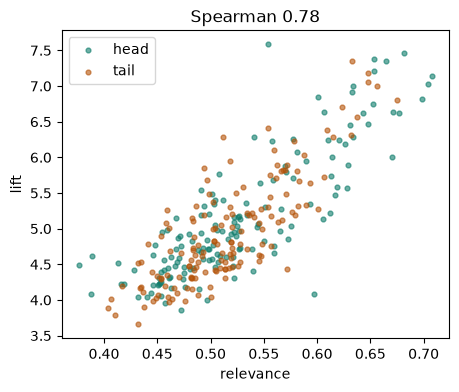

In [6]:
from scipy.stats import spearmanr, pearsonr
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

rho = spearmanr(df["lift"], df["relevance"]).correlation
r   = pearsonr(df["lift"], df["relevance"])[0]
print(f"corr(lift, relevance): Spearman {rho:.3f} | Pearson {r:.3f}")

def oof_auc(cols, target, d):
    """Out-of-fold AUROC of a logistic regression on these columns."""
    cv = StratifiedKFold(5, shuffle=True, random_state=seed)
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    p = cross_val_predict(m, d[cols], d[target], cv=cv, method="predict_proba")[:, 1]
    return auroc_ci(d[target], p, n_boot, seed=seed)

added = []
for t in targets:
    a_rel = oof_auc(["relevance"], t, df)
    a_both = oof_auc(["relevance", "lift"], t, df)
    added.append({"label": t, "relevance_only": a_rel[0], "relevance+lift": a_both[0],
                  "gain": a_both[0] - a_rel[0]})
added = pd.DataFrame(added).set_index("label")
display(added.round(3))

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(5, 4))
for band, c in [("head", "#0E7C6B"), ("tail", "#B45309")]:
    s = df[df["band"] == band]
    ax.scatter(s["relevance"], s["lift"], s=12, alpha=.6, label=band, color=c)
ax.set_xlabel("relevance"); ax.set_ylabel("lift"); ax.legend(); ax.set_title(f"Spearman {rho:.2f}")
plt.show()

## 4. Inside head only, and inside tail only

In [7]:
wb = {t: within_band_auroc(df, signals, t, n_boot=n_boot, seed=seed) for t in targets}
for t, tab in wb.items():
    print(f"\n=== label={t} ==="); display(tab.round(3))


=== label=y_judge ===


auroc           low          high       
band          head   tail   head   tail   head   tail
signal                                               
cas          0.828  0.788  0.753  0.713  0.895  0.859
cas_mean     0.666  0.685  0.574  0.599  0.754  0.765
clarity      0.422  0.573  0.332  0.478  0.519  0.668
consistency  0.719  0.567  0.630  0.474  0.799  0.657
kw_coverage  0.598  0.674  0.511  0.587  0.688  0.762
lift         0.747  0.707  0.662  0.621  0.820  0.784
relevance    0.776  0.727  0.684  0.644  0.854  0.806


=== label=y_cov ===


auroc           low          high       
band          head   tail   head   tail   head   tail
signal                                               
cas          0.875  0.790  0.807  0.706  0.930  0.865
cas_mean     0.748  0.706  0.666  0.615  0.825  0.787
clarity      0.323  0.504  0.244  0.407  0.417  0.602
consistency  0.750  0.585  0.662  0.496  0.825  0.678
kw_coverage  0.672  0.676  0.589  0.594  0.753  0.762
lift         0.816  0.691  0.738  0.607  0.879  0.773
relevance    0.850  0.736  0.771  0.655  0.913  0.812


=== label=y_gen ===


auroc           low          high       
band          head   tail   head   tail   head   tail
signal                                               
cas          0.881  0.775  0.811  0.691  0.942  0.855
cas_mean     0.722  0.640  0.626  0.548  0.809  0.724
clarity      0.401  0.547  0.307  0.447  0.502  0.645
consistency  0.706  0.557  0.609  0.458  0.793  0.655
kw_coverage  0.643  0.674  0.555  0.589  0.733  0.761
lift         0.768  0.720  0.676  0.636  0.844  0.798
relevance    0.810  0.730  0.720  0.649  0.881  0.809

## 5. Step 1 decision
Rule: warn if corr(lift, relevance) > 0.9 **or** Lift adds no AUROC on top of relevance
(gain ≤ 0.01). Either one on its own is enough to change Lift's background sample
(hard negatives) before scaling up.

The rule used to need **both** halves. That was too soft: Lift can sit well below 0.9
correlation and still carry no extra information about the label, which is the thing
this check exists to catch.

In [8]:
alarm = cfg["eval"]["lift_relevance_alarm"]
main = targets[0]
gain = float(added.loc[main, "gain"])
too_close = bool(abs(rho) > alarm)      # bool(), so the saved JSON says true/false not 1.0/0.0
adds_nothing = bool(gain <= 0.01)
print(f"corr(lift, relevance) = {rho:.3f}  (alarm above {alarm})  -> {'FAIL' if too_close else 'ok'}")
print(f"AUROC gain from adding Lift ({main}) = {gain:+.3f}  (alarm at or below +0.010)"
      f"  -> {'FAIL' if adds_nothing else 'ok'}")

# Warn if EITHER half fires: both are ways of saying Lift is relevance again.
if too_close or adds_nothing:
    why = []
    if too_close:
        why.append(f"it moves with relevance (Spearman {rho:.3f})")
    if adds_nothing:
        why.append(f"it adds no AUROC on top of relevance ({gain:+.3f})")
    print("\nDECISION: Lift ≈ relevance, because " + " and ".join(why) + ".")
    print("Change the background sample (hard negatives) before scaling up.")
else:
    print("\nDECISION: Lift is distinct enough. Go ahead with Step 2 as planned.")

out = {"corr_lift_relevance_spearman": float(rho), "corr_lift_relevance_pearson": float(r),
       "lift_gain": added.round(4).to_dict(),
       "decision": {"rule": "warn if gain <= 0.01 OR |spearman| > alarm",
                    "alarm": alarm, "too_close": too_close,
                    "adds_nothing": adds_nothing, "warn": too_close or adds_nothing},
       "signal_tables": {k: v.round(4).to_dict() for k, v in tables.items()}}
res = data_path(cfg, "step1_quick_checks.json")
json.dump(out, open(res, "w"), indent=2, default=float)
print("saved", res)

corr(lift, relevance) = 0.783  (alarm above 0.9)  -> ok
AUROC gain from adding Lift (y_judge) = -0.001  (alarm at or below +0.010)  -> FAIL

DECISION: Lift ≈ relevance, because it adds no AUROC on top of relevance (-0.001).
Change the background sample (hard negatives) before scaling up.


saved E:\shaithu\4th Year\IRP\halt-rag-repo\HALT-RAG\data\step1_quick_checks.json
